In [ ]:

# TASK 1: Import Libraries and Load Dataset

import os
import zipfile
import glob
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Upload Kaggle ZIP dataset
uploaded = files.upload()

# Extract ZIP file
zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/hate_dataset')

# Find CSV files
csv_files = glob.glob('/content/hate_dataset/**/*.csv', recursive=True)

print("Available CSV files:", csv_files)

# Load dataset
if not csv_files:
    raise FileNotFoundError("No CSV file found in the uploaded ZIP.")

df = pd.read_csv(csv_files[0])

# Display dataset
print("\nDataset loaded successfully!")
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Saving labeled_data.csv.zip to labeled_data.csv (1).zip
Available CSV files: ['/content/hate_dataset/labeled_data.csv']

Dataset loaded successfully!
Dataset Shape: (24783, 7)

First 5 Rows:


,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...



Column Names:
['Unnamed: 0', 'count', 'hate_speech', 'offensive_language', 'neither', 'class', 'tweet']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24783 entries, 0 to 24782
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Unnamed: 0          24783 non-null  int64 
 1   count               24783 non-null  int64 
 2   hate_speech         24783 non-null  int64 
 3   offensive_language  24783 non-null  int64 
 4   neither             24783 non-null  int64 
 5   class               24783 non-null  int64 
 6   tweet               24783 non-null  object
dtypes: int64(6), object(1)
memory usage: 1.3+ MB


In [ ]:

# TASK 2: Data Preprocessing

import re

# Select required columns
df = df[['tweet', 'class']]

# Remove missing values
df = df.dropna()

# Remove duplicate rows
df = df.drop_duplicates()

# Convert text into lowercase
df['tweet'] = df['tweet'].astype(str).str.lower()

# Clean text
def clean_text(text):
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df['tweet'] = df['tweet'].apply(clean_text)

# Remove empty tweets
df = df[df['tweet'] != '']

# Convert class labels
# 0 = Hate Speech
# 1 = Offensive Language
# 2 = Neither

df['class'] = df['class'].astype(int)

print("Data preprocessing completed!")
print("\nDataset Shape:", df.shape)

print("\nFirst 5 Cleaned Tweets:")
display(df.head())

print("\nClass Distribution:")
print(df['class'].value_counts())


Data preprocessing completed!

Dataset Shape: (24781, 2)

First 5 Cleaned Tweets:


,tweet,class
0,rt as a woman you shouldnt complain about clea...,2
1,rt boy dats coldtyga dwn bad for cuffin dat ho...,1
2,rt dawg rt you ever fuck a bitch and she start...,1
3,rt she look like a tranny,1
4,rt the shit you hear about me might be true or...,1



Class Distribution:
class
1    19189
2     4162
0     1430
Name: count, dtype: int64


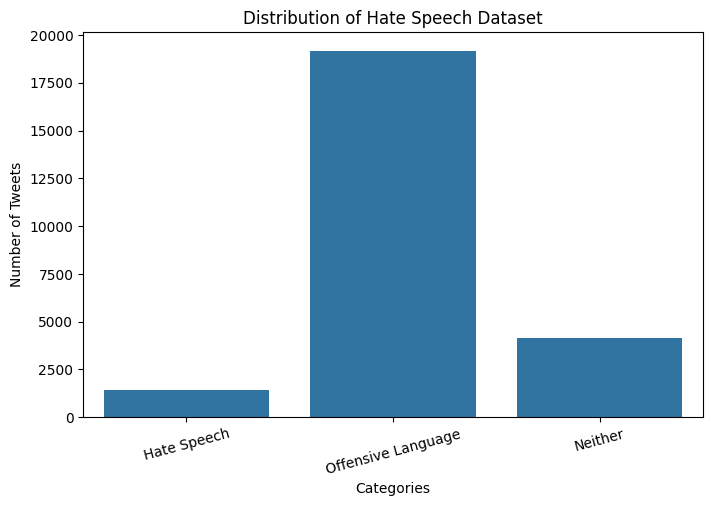

Class Distribution:
Hate Speech : 1430
Offensive Language : 19189
Neither : 4162


In [ ]:

# TASK 3: Data Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Count each class
class_counts = df['class'].value_counts().sort_index()

# Class names
class_names = {
    0: 'Hate Speech',
    1: 'Offensive Language',
    2: 'Neither'
}

labels = [class_names[i] for i in class_counts.index]

# Plot bar chart
plt.figure(figsize=(8, 5))

sns.barplot(x=labels, y=class_counts.values)

plt.title("Distribution of Hate Speech Dataset")
plt.xlabel("Categories")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=15)

plt.show()

# Display class counts
print("Class Distribution:")
for i, count in class_counts.items():
    print(class_names[i], ":", count)


In [ ]:

# TASK 4: Text Tokenization and Vocabulary Creation

from collections import Counter

# Tokenize tweets
df['tokens'] = df['tweet'].apply(lambda x: x.split())

# Create vocabulary
word_counts = Counter(
    word for tokens in df['tokens'] for word in tokens
)

vocab = {
    word: idx + 2
    for idx, (word, count) in enumerate(word_counts.items())
}

# Special tokens
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

# Convert words into numerical sequences
def encode_text(tokens):
    return [vocab.get(word, 1) for word in tokens]

df['encoded'] = df['tokens'].apply(encode_text)

# Padding sequences
MAX_LEN = 50

def pad_sequence(sequence):
    sequence = sequence[:MAX_LEN]
    return sequence + [0] * (MAX_LEN - len(sequence))

df['padded'] = df['encoded'].apply(pad_sequence)

# Display results
print("Tokenization completed!")
print("Vocabulary Size:", len(vocab))

print("\nOriginal Tweet:")
print(df['tweet'].iloc[0])

print("\nTokens:")
print(df['tokens'].iloc[0])

print("\nEncoded Sequence:")
print(df['encoded'].iloc[0])

print("\nPadded Sequence:")
print(df['padded'].iloc[0])


Tokenization completed!
Vocabulary Size: 21774

Original Tweet:
rt as a woman you shouldnt complain about cleaning up your house amp as a man you should always take the trash out

Tokens:
['rt', 'as', 'a', 'woman', 'you', 'shouldnt', 'complain', 'about', 'cleaning', 'up', 'your', 'house', 'amp', 'as', 'a', 'man', 'you', 'should', 'always', 'take', 'the', 'trash', 'out']

Encoded Sequence:
[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 3, 4, 15, 6, 16, 17, 18, 19, 20, 21]

Padded Sequence:
[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 3, 4, 15, 6, 16, 17, 18, 19, 20, 21, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [ ]:

# TASK 5: Train-Test Split and DataLoader

from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

# Prepare input and output
X = np.array(df['padded'].tolist(), dtype=np.int64)
y = df['class'].values.astype(np.int64)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert into PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.long)
X_test = torch.tensor(X_test, dtype=torch.long)

y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

# Create datasets
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

# Create DataLoaders
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train-Test Split Completed!")
print("Training Samples:", len(train_dataset))
print("Testing Samples:", len(test_dataset))
print("Batch Size:", BATCH_SIZE)

print("\nInput Shape:", X_train.shape)
print("Output Shape:", y_train.shape)


Train-Test Split Completed!
Training Samples: 19824
Testing Samples: 4957
Batch Size: 64

Input Shape: torch.Size([19824, 50])
Output Shape: torch.Size([19824])


In [ ]:

# TASK 6: Build RNN Model

import torch.nn as nn

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using Device:", device)

# RNN Model
class RNNModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim):
        super(RNNModel, self).__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.rnn = nn.RNN(
            embedding_dim,
            hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        embedded = self.embedding(x)

        output, hidden = self.rnn(embedded)

        output = self.fc(hidden[-1])

        return output

# Model parameters
vocab_size = len(vocab)
embedding_dim = 100
hidden_dim = 128
output_dim = 3

# Create model
rnn_model = RNNModel(
    vocab_size,
    embedding_dim,
    hidden_dim,
    output_dim
).to(device)

print("\nRNN Model Created Successfully!")
print(rnn_model)


Using Device: cpu

RNN Model Created Successfully!
RNNModel(
  (embedding): Embedding(21774, 100, padding_idx=0)
  (rnn): RNN(100, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)


In [ ]:

# TASK 7: Train RNN Model

import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(rnn_model.parameters(), lr=0.001)

# Number of epochs
epochs = 5

rnn_train_losses = []
rnn_train_accuracies = []

# Training loop
for epoch in range(epochs):

    rnn_model.train()

    total_loss = 0
    correct = 0
    total = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = rnn_model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    avg_loss = total_loss / len(train_loader)
    accuracy = 100 * correct / total

    rnn_train_losses.append(avg_loss)
    rnn_train_accuracies.append(accuracy)

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {avg_loss:.4f} "
          f"Accuracy: {accuracy:.2f}%")

print("\nRNN Training Completed Successfully!")


Epoch [1/5] Loss: 0.6742 Accuracy: 77.24%
Epoch [2/5] Loss: 0.6639 Accuracy: 77.44%
Epoch [3/5] Loss: 0.6642 Accuracy: 77.44%
Epoch [4/5] Loss: 0.6634 Accuracy: 77.44%
Epoch [5/5] Loss: 0.6641 Accuracy: 77.44%

RNN Training Completed Successfully!


RNN MODEL EVALUATION
---------------------
Accuracy : 77.43 %
Precision: 25.81 %
Recall   : 33.33 %
F1 Score : 29.09 %

Classification Report:
                    precision    recall  f1-score   support

       Hate Speech       0.00      0.00      0.00       286
Offensive Language       0.77      1.00      0.87      3838
           Neither       0.00      0.00      0.00       833

          accuracy                           0.77      4957
         macro avg       0.26      0.33      0.29      4957
      weighted avg       0.60      0.77      0.68      4957



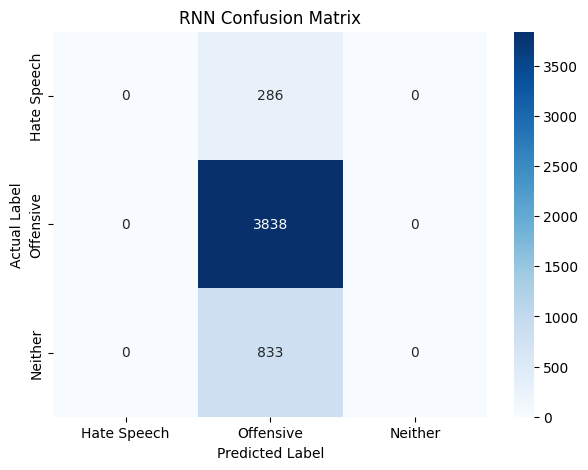

In [ ]:

# TASK 8: RNN Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Evaluate RNN model
rnn_model.eval()

y_true = []
y_pred = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        outputs = rnn_model(inputs)

        _, predicted = torch.max(outputs, 1)

        y_true.extend(labels.numpy())
        y_pred.extend(predicted.cpu().numpy())

# Calculate metrics
rnn_accuracy = accuracy_score(y_true, y_pred)

rnn_precision = precision_score(
    y_true, y_pred, average='macro', zero_division=0
)

rnn_recall = recall_score(
    y_true, y_pred, average='macro', zero_division=0
)

rnn_f1 = f1_score(
    y_true, y_pred, average='macro', zero_division=0
)

print("RNN MODEL EVALUATION")
print("---------------------")
print("Accuracy :", round(rnn_accuracy * 100, 2), "%")
print("Precision:", round(rnn_precision * 100, 2), "%")
print("Recall   :", round(rnn_recall * 100, 2), "%")
print("F1 Score :", round(rnn_f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=['Hate Speech', 'Offensive Language', 'Neither'],
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Hate Speech', 'Offensive', 'Neither'],
    yticklabels=['Hate Speech', 'Offensive', 'Neither']
)

plt.title("RNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


In [ ]:

# TASK 9: Build LSTM Model

import torch.nn as nn

class LSTMModel(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim):
        super(LSTMModel, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):

        embedded = self.embedding(x)

        output, (hidden, cell) = self.lstm(embedded)

        output = self.fc(hidden[-1])

        return output


# Model parameters
vocab_size = len(vocab)
embedding_dim = 100
hidden_dim = 128
output_dim = 3

# Create LSTM model
lstm_model = LSTMModel(
    vocab_size,
    embedding_dim,
    hidden_dim,
    output_dim
).to(device)

print("LSTM Model Created Successfully!")
print(lstm_model)


LSTM Model Created Successfully!
LSTMModel(
  (embedding): Embedding(21774, 100, padding_idx=0)
  (lstm): LSTM(100, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)


In [ ]:

# TASK 9: Build LSTM Model

import torch.nn as nn

class LSTMModel(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim):
        super(LSTMModel, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):

        embedded = self.embedding(x)

        output, (hidden, cell) = self.lstm(embedded)

        output = self.fc(hidden[-1])

        return output


# Model parameters
vocab_size = len(vocab)
embedding_dim = 100
hidden_dim = 128
output_dim = 3

# Create LSTM model
lstm_model = LSTMModel(
    vocab_size,
    embedding_dim,
    hidden_dim,
    output_dim
).to(device)

print("LSTM Model Created Successfully!")
print(lstm_model)


LSTM Model Created Successfully!
LSTMModel(
  (embedding): Embedding(21774, 100, padding_idx=0)
  (lstm): LSTM(100, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)


In [ ]:

# TASK 10: Train LSTM Model

import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(lstm_model.parameters(), lr=0.001)

# Training parameters
epochs = 5

lstm_train_losses = []
lstm_train_accuracies = []

# Training loop
for epoch in range(epochs):

    lstm_model.train()

    total_loss = 0
    correct = 0
    total = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = lstm_model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    avg_loss = total_loss / len(train_loader)
    accuracy = 100 * correct / total

    lstm_train_losses.append(avg_loss)
    lstm_train_accuracies.append(accuracy)

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {avg_loss:.4f} "
          f"Accuracy: {accuracy:.2f}%")

print("\nLSTM Training Completed Successfully!")


Epoch [1/5] Loss: 0.6826 Accuracy: 77.01%
Epoch [2/5] Loss: 0.6631 Accuracy: 77.42%
Epoch [3/5] Loss: 0.5980 Accuracy: 79.42%
Epoch [4/5] Loss: 0.5753 Accuracy: 80.46%
Epoch [5/5] Loss: 0.5743 Accuracy: 80.64%

LSTM Training Completed Successfully!


LSTM MODEL EVALUATION
----------------------
Accuracy : 80.55 %
Precision: 46.77 %
Recall   : 48.12 %
F1 Score : 47.38 %

Classification Report:
                    precision    recall  f1-score   support

       Hate Speech       0.00      0.00      0.00       286
Offensive Language       0.85      0.93      0.89      3838
           Neither       0.55      0.52      0.53       833

          accuracy                           0.81      4957
         macro avg       0.47      0.48      0.47      4957
      weighted avg       0.75      0.81      0.78      4957



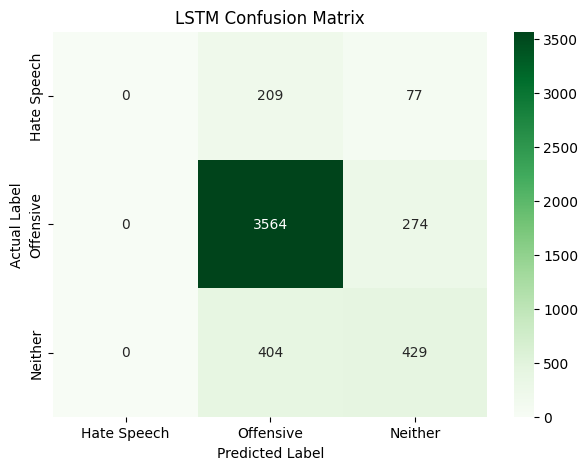

In [ ]:

# TASK 11: LSTM Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Evaluate LSTM model
lstm_model.eval()

y_true_lstm = []
y_pred_lstm = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        outputs = lstm_model(inputs)

        _, predicted = torch.max(outputs, 1)

        y_true_lstm.extend(labels.numpy())
        y_pred_lstm.extend(predicted.cpu().numpy())

# Calculate metrics
lstm_accuracy = accuracy_score(y_true_lstm, y_pred_lstm)

lstm_precision = precision_score(
    y_true_lstm, y_pred_lstm,
    average='macro', zero_division=0
)

lstm_recall = recall_score(
    y_true_lstm, y_pred_lstm,
    average='macro', zero_division=0
)

lstm_f1 = f1_score(
    y_true_lstm, y_pred_lstm,
    average='macro', zero_division=0
)

print("LSTM MODEL EVALUATION")
print("----------------------")
print("Accuracy :", round(lstm_accuracy * 100, 2), "%")
print("Precision:", round(lstm_precision * 100, 2), "%")
print("Recall   :", round(lstm_recall * 100, 2), "%")
print("F1 Score :", round(lstm_f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_true_lstm,
    y_pred_lstm,
    target_names=[
        'Hate Speech',
        'Offensive Language',
        'Neither'
    ],
    zero_division=0
))

# Confusion Matrix
cm_lstm = confusion_matrix(y_true_lstm, y_pred_lstm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Hate Speech', 'Offensive', 'Neither'],
    yticklabels=['Hate Speech', 'Offensive', 'Neither']
)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


In [ ]:

# TASK 12: Build GRU Model

import torch.nn as nn

class GRUModel(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim):
        super(GRUModel, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )

        self.gru = nn.GRU(
            embedding_dim,
            hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):

        embedded = self.embedding(x)

        output, hidden = self.gru(embedded)

        output = self.fc(hidden[-1])

        return output


# Model parameters
vocab_size = len(vocab)
embedding_dim = 100
hidden_dim = 128
output_dim = 3

# Create GRU model
gru_model = GRUModel(
    vocab_size,
    embedding_dim,
    hidden_dim,
    output_dim
).to(device)

print("GRU Model Created Successfully!")
print(gru_model)


GRU Model Created Successfully!
GRUModel(
  (embedding): Embedding(21774, 100, padding_idx=0)
  (gru): GRU(100, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)


In [ ]:

# TASK 13: Train GRU Model

import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(gru_model.parameters(), lr=0.001)

# Training parameters
epochs = 5

gru_train_losses = []
gru_train_accuracies = []

# Training loop
for epoch in range(epochs):

    gru_model.train()

    total_loss = 0
    correct = 0
    total = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = gru_model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    avg_loss = total_loss / len(train_loader)
    accuracy = 100 * correct / total

    gru_train_losses.append(avg_loss)
    gru_train_accuracies.append(accuracy)

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {avg_loss:.4f} "
          f"Accuracy: {accuracy:.2f}%")

print("\nGRU Training Completed Successfully!")


Epoch [1/5] Loss: 0.5340 Accuracy: 78.72%
Epoch [2/5] Loss: 0.4059 Accuracy: 81.97%
Epoch [3/5] Loss: 0.3549 Accuracy: 85.91%
Epoch [4/5] Loss: 0.2695 Accuracy: 89.97%
Epoch [5/5] Loss: 0.2143 Accuracy: 92.27%

GRU Training Completed Successfully!


GRU MODEL EVALUATION
---------------------
Accuracy : 88.54 %
Precision: 79.88 %
Recall   : 60.39 %
F1 Score : 61.73 %

Classification Report:
                    precision    recall  f1-score   support

       Hate Speech       0.67      0.06      0.12       286
Offensive Language       0.90      0.97      0.93      3838
           Neither       0.83      0.78      0.81       833

          accuracy                           0.89      4957
         macro avg       0.80      0.60      0.62      4957
      weighted avg       0.87      0.89      0.86      4957



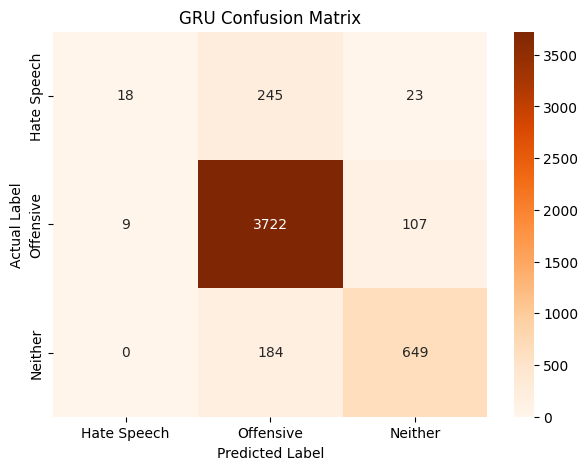

In [ ]:

# TASK 14: GRU Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Evaluate GRU model
gru_model.eval()

y_true_gru = []
y_pred_gru = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        outputs = gru_model(inputs)

        _, predicted = torch.max(outputs, 1)

        y_true_gru.extend(labels.numpy())
        y_pred_gru.extend(predicted.cpu().numpy())

# Calculate metrics
gru_accuracy = accuracy_score(y_true_gru, y_pred_gru)

gru_precision = precision_score(
    y_true_gru, y_pred_gru,
    average='macro', zero_division=0
)

gru_recall = recall_score(
    y_true_gru, y_pred_gru,
    average='macro', zero_division=0
)

gru_f1 = f1_score(
    y_true_gru, y_pred_gru,
    average='macro', zero_division=0
)

print("GRU MODEL EVALUATION")
print("---------------------")
print("Accuracy :", round(gru_accuracy * 100, 2), "%")
print("Precision:", round(gru_precision * 100, 2), "%")
print("Recall   :", round(gru_recall * 100, 2), "%")
print("F1 Score :", round(gru_f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_true_gru,
    y_pred_gru,
    target_names=[
        'Hate Speech',
        'Offensive Language',
        'Neither'
    ],
    zero_division=0
))

# Confusion Matrix
cm_gru = confusion_matrix(y_true_gru, y_pred_gru)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_gru,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Hate Speech', 'Offensive', 'Neither'],
    yticklabels=['Hate Speech', 'Offensive', 'Neither']
)

plt.title("GRU Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,RNN,77.43,25.81,33.33,29.09
1,LSTM,80.55,46.77,48.12,47.38
2,GRU,88.54,79.88,60.39,61.73


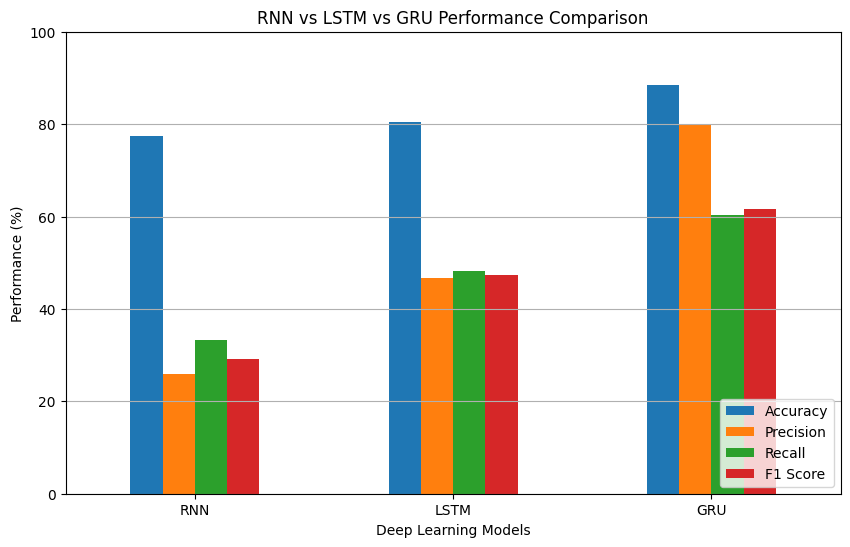


Best Performing Model:
Model: GRU
F1 Score: 61.73 %


In [ ]:

# TASK 15: Comparison of RNN, LSTM and GRU

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create comparison table
comparison = pd.DataFrame({
    'Model': ['RNN', 'LSTM', 'GRU'],

    'Accuracy': [
        rnn_accuracy * 100,
        lstm_accuracy * 100,
        gru_accuracy * 100
    ],

    'Precision': [
        rnn_precision * 100,
        lstm_precision * 100,
        gru_precision * 100
    ],

    'Recall': [
        rnn_recall * 100,
        lstm_recall * 100,
        gru_recall * 100
    ],

    'F1 Score': [
        rnn_f1 * 100,
        lstm_f1 * 100,
        gru_f1 * 100
    ]
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison.round(2))

# Plot comparison graph
comparison_plot = comparison.set_index('Model')

comparison_plot.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("RNN vs LSTM vs GRU Performance Comparison")
plt.xlabel("Deep Learning Models")
plt.ylabel("Performance (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y')
plt.show()

# Find best model based on F1-score
best_model = comparison.loc[
    comparison['F1 Score'].idxmax()
]

print("\nBest Performing Model:")
print("Model:", best_model['Model'])
print("F1 Score:", round(best_model['F1 Score'], 2), "%")


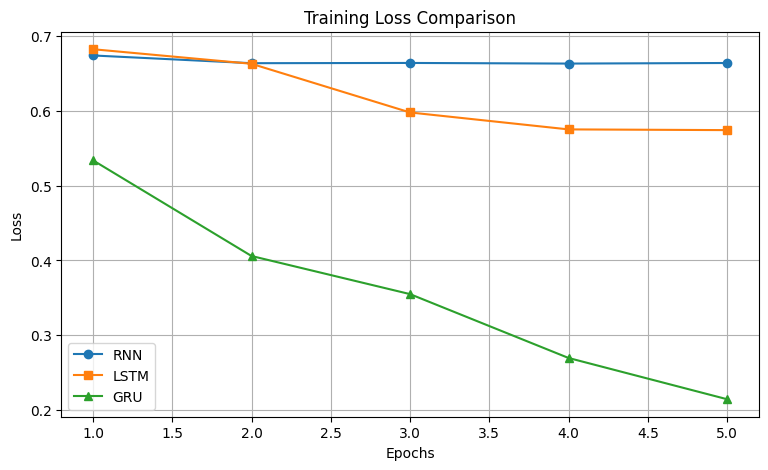

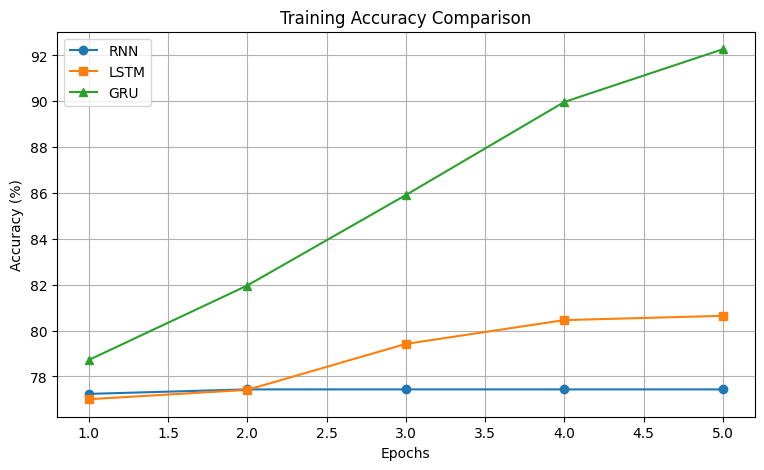

Training graphs generated successfully!


In [ ]:

# TASK 16: Training Loss and Accuracy Graphs

epochs_range = range(1, 6)

# Training Loss Comparison
plt.figure(figsize=(9, 5))

plt.plot(epochs_range, rnn_train_losses, marker='o', label='RNN')
plt.plot(epochs_range, lstm_train_losses, marker='s', label='LSTM')
plt.plot(epochs_range, gru_train_losses, marker='^', label='GRU')

plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


# Training Accuracy Comparison
plt.figure(figsize=(9, 5))

plt.plot(epochs_range, rnn_train_accuracies, marker='o', label='RNN')
plt.plot(epochs_range, lstm_train_accuracies, marker='s', label='LSTM')
plt.plot(epochs_range, gru_train_accuracies, marker='^', label='GRU')

plt.title("Training Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid()
plt.show()

print("Training graphs generated successfully!")


In [ ]:

# TASK 17: Hate Speech Prediction on New Text

# Select best model based on F1-score
models = {
    'RNN': rnn_model,
    'LSTM': lstm_model,
    'GRU': gru_model
}

best_model_name = best_model['Model']
selected_model = models[best_model_name]

selected_model.eval()

# Class labels
class_names = {
    0: "Hate Speech",
    1: "Offensive Language",
    2: "Neither"
}

# Prediction function
def predict_hate_speech(text):

    text = clean_text(text)

    tokens = text.split()

    encoded = [vocab.get(word, 1) for word in tokens]

    padded = encoded[:MAX_LEN]
    padded += [0] * (MAX_LEN - len(padded))

    input_tensor = torch.tensor(
        [padded], dtype=torch.long
    ).to(device)

    with torch.no_grad():

        output = selected_model(input_tensor)

        probabilities = torch.softmax(output, dim=1)

        prediction = torch.argmax(probabilities, dim=1).item()

    print("Input Text:", text)
    print("Predicted Category:", class_names[prediction])
    print("Confidence:", round(probabilities[0][prediction].item() * 100, 2), "%")


# Test sentences
test_sentences = [
    "I hate you and your community",
    "You are a stupid person",
    "Have a wonderful day"
]

print("Using Best Model:", best_model_name)

for sentence in test_sentences:
    print("\n--------------------------")
    predict_hate_speech(sentence)


Using Best Model: GRU

--------------------------
Input Text: I hate you and your community
Predicted Category: Offensive Language
Confidence: 80.4 %

--------------------------
Input Text: You are a stupid person
Predicted Category: Offensive Language
Confidence: 50.4 %

--------------------------
Input Text: Have a wonderful day
Predicted Category: Neither
Confidence: 83.36 %


In [ ]:

# TASK 18: Final Project Results and Conclusion

# Display final results
print("HATE SPEECH DETECTION USING DEEP LEARNING")
print("=" * 50)

print("\nMODEL PERFORMANCE")

print("\nRNN Accuracy  :", round(rnn_accuracy * 100, 2), "%")
print("LSTM Accuracy :", round(lstm_accuracy * 100, 2), "%")
print("GRU Accuracy  :", round(gru_accuracy * 100, 2), "%")

# Find best model
best_model_name = comparison.loc[
    comparison['F1 Score'].idxmax(), 'Model'
]

best_f1 = comparison['F1 Score'].max()

print("\nBest Performing Model:", best_model_name)
print("Best F1 Score:", round(best_f1, 2), "%")

print("\nPROJECT CONCLUSION")
print("-" * 50)

print("""
Hate Speech Detection using Deep Learning was
successfully implemented.

The project uses text preprocessing and tokenization
to prepare the dataset.

Three deep learning models were developed:
1. Recurrent Neural Network (RNN)
2. Long Short-Term Memory (LSTM)
3. Gated Recurrent Unit (GRU)

All three models were trained and evaluated using
Accuracy, Precision, Recall and F1-score.

The models were compared to identify the best
performing model.

The system predicts whether a given text belongs to
Hate Speech, Offensive Language or Neither.

This project helps in identifying harmful language
in online text and supports safer online communication.
""")

print("PROJECT COMPLETED SUCCESSFULLY!")


HATE SPEECH DETECTION USING DEEP LEARNING

MODEL PERFORMANCE

RNN Accuracy  : 77.43 %
LSTM Accuracy : 80.55 %
GRU Accuracy  : 88.54 %

Best Performing Model: GRU
Best F1 Score: 61.73 %

PROJECT CONCLUSION
--------------------------------------------------

Hate Speech Detection using Deep Learning was
successfully implemented.

The project uses text preprocessing and tokenization
to prepare the dataset.

Three deep learning models were developed:
1. Recurrent Neural Network (RNN)
2. Long Short-Term Memory (LSTM)
3. Gated Recurrent Unit (GRU)

All three models were trained and evaluated using
Accuracy, Precision, Recall and F1-score.

The models were compared to identify the best
performing model.

The system predicts whether a given text belongs to
Hate Speech, Offensive Language or Neither.

This project helps in identifying harmful language
in online text and supports safer online communication.

PROJECT COMPLETED SUCCESSFULLY!
